# **Introduction to Pothole Object Detection**

Object detection is a key computer vision task used to identify and locate objects in images or videos. It has applications in infrastructure monitoring, traffic analysis, surveillance, and industrial inspection. The typical workflow includes collecting datasets, annotating them using labeling tools, and training deep learning models with frameworks like YOLO. Google Colab is widely used for model training and experimentation due to its easy setup and GPU support, enabling efficient development.

**Useful Resources**

<a href="https://labelstud.io/" target="_blank">Label Studio</a>

<a href="https://labelstud.io/guide/" target="_blank">Label Studio Documentation — Quick Start Guide</a>

<a href="https://roboflow.com/" target="_blank">Roboflow: Computer Vision Tools</a>

<a href="https://storage.googleapis.com/openimages/web/index.html" target="_blank">Open Images V7 Dataset</a>t

<a href="https://www.kaggle.com/" target="_blank">Kaggle: Datasets & Competitions</a>


Next make sure to downlaod the zip file name it has "data" and saved inside Documents

Also make sure the files are organized in the same folder structure as shown below.


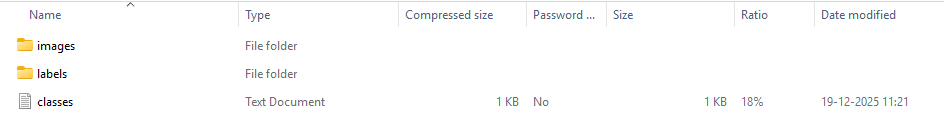

# **Uploading images**

Drag and Drap your "data" ZIP folder here

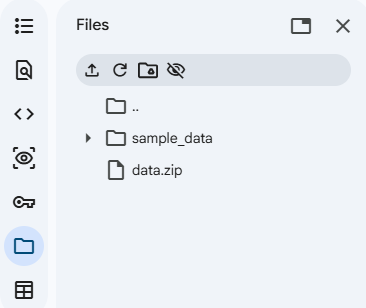

# **After labelling your images**

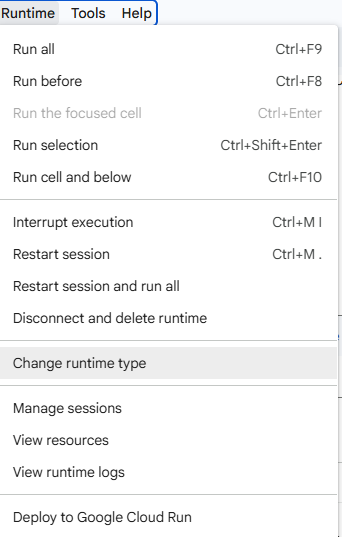

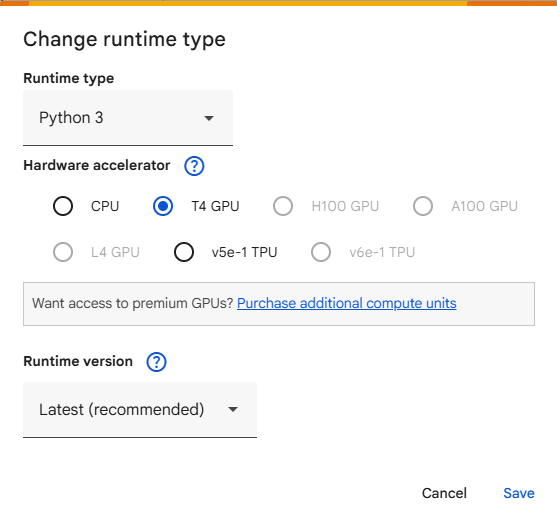

Click save

**Check your GPU information**

In [ ]:
!nvidia-smi

**Unzip Your ZIP file**

In [ ]:
!unzip -q /content/data.zip -d /content/custom_data

**Label format detection cell**

This checks if your dataset has labels in "txt" or jason" format.
NOTE:
If your labels folder contains files in txt format then ignore this step and next step.

In [ ]:
import os

labels_dir = "/content/custom_data/labels"

has_yolo_labels = False
has_json_labels = False

if os.path.exists(labels_dir):
    for f in os.listdir(labels_dir):
        if f.endswith(".txt"):
            has_yolo_labels = True
        if f.endswith(".json"):
            has_json_labels = True

print("YOLO label TXT found:", has_yolo_labels)
print("JSON label found:", has_json_labels)



**Convert JSON --> TXT (optional, if your labels are in txt format, run only when the format is in JSON)**

In [ ]:
if has_json_labels and not has_yolo_labels:
    import json
    import os
    from PIL import Image

    labels_dir = "/content/custom_data/labels"
    images_dir = "/content/custom_data/images"
    classes_path = "/content/custom_data/classes.txt"

    os.makedirs(labels_dir, exist_ok=True)

    # Load class list
    with open(classes_path) as f:
        class_names = [c.strip() for c in f.readlines()]

    class_to_id = {name: idx for idx, name in enumerate(class_names)}

    json_files = [f for f in os.listdir(labels_dir) if f.endswith(".json")]

    for jf in json_files:
        with open(os.path.join(labels_dir, jf)) as f:
            data = json.load(f)

        img_name = os.path.splitext(jf)[0]
        label_file = os.path.join(labels_dir, img_name + ".txt")

        img_path = os.path.join(images_dir, img_name + ".jpg")
        if not os.path.exists(img_path):
            img_path = os.path.join(images_dir, img_name + ".png")

        img_w, img_h = Image.open(img_path).size

        for shape in data["shapes"]:
            label = shape["label"]
            points = shape["points"]

            # Rectangle box
            (x1, y1), (x2, y2) = points

            x_center = ((x1 + x2) / 2) / img_w
            y_center = ((y1 + y2) / 2) / img_h
            w = abs(x2 - x1) / img_w
            h = abs(y2 - y1) / img_h

            class_id = class_to_id[label]

            with open(label_file, "a") as f:
                f.write(f"{class_id} {x_center} {y_center} {w} {h}\n")

    print("JSON labels successfully converted to YOLO TXT.")
else:
    print("Skipping conversion — YOLO labels already exist.")



**The below code is run to prepare your dataset for YOLO object detection by splitting it into training and validation sets. Without this step, the model wouldn’t know which images to learn from and which to use for evaluation.**

In [ ]:
!wget -O /content/train_val_split.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py
!python train_val_split.py --datapath="/content/custom_data" --train_pct=0.9

**Install (Ultralytics)**

In [ ]:
!pip install ultralytics

When you train a YOLO model, it needs a configuration file called data.yaml that tells it:

Where your images are stored for training and validation.

How many classes you want to detect.

The names of these classes.

Without this file, YOLO doesn’t know what to train on.

This code reads your classes.txt file, counts the classes, and automatically creates a properly formatted data.yaml file with the paths to training and validation images, number of classes, and class names for YOLO training.





In [ ]:
# Python function to automatically create data.yaml config file
# 1. Reads "classes.txt" file to get list of class names
# 2. Creates data dictionary with correct paths to folders, number of classes, and names of classes
# 3. Writes data in YAML format to data.yaml

import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):

  # Read class.txt to get class names
  if not os.path.exists(path_to_classes_txt):
    print(f'classes.txt file not found! Please create a classes.txt labelmap and move it to {path_to_classes_txt}')
    return
  with open(path_to_classes_txt, 'r') as f:
    classes = []
    for line in f.readlines():
      if len(line.strip()) == 0: continue
      classes.append(line.strip())
  number_of_classes = len(classes)

  # Create data dictionary
  data = {
      'path': '/content/data',
      'train': 'train/images',
      'val': 'validation/images',
      'nc': number_of_classes,
      'names': classes
  }

  # Write data to YAML file
  with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)
  print(f'Created config file at {path_to_data_yaml}')

  return

# Define path to classes.txt and run function
path_to_classes_txt = '/content/custom_data/classes.txt'
path_to_data_yaml = '/content/data.yaml'

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

print('\nFile contents:\n')
!cat /content/data.yaml

## **Run the trained model**

**Number of Epochs (epochs)**

An epoch refers to one complete pass through your entire training dataset. Setting the number of epochs determines how long the model trains. The optimal number depends on both your dataset size and the model you choose:

For datasets under 200 images → start with 60 epochs

For datasets over 200 images → start with 40 epochs

**Image Resolution (imgsz)**

The resolution you train your model at strongly affects both speed and accuracy. Higher resolutions improve accuracy but slow down processing, while lower resolutions increase speed but may reduce precision. YOLO models commonly use 640×640, but for faster inference or low-resolution images, you can try 480×480.

In [ ]:
!yolo detect train data=/content/data.yaml model=yolo11s.pt epochs=60 imgsz=640

# **Test the Model**

Once training is complete, the next step is to evaluate your model. The commands below will run the model on the images in your validation folder and display results for the first 10 images. This helps you quickly check that your model is performing as expected. Simply click Play on the code blocks to see the predictions in action.

In [ ]:
!yolo detect predict model=runs/detect/train/weights/best.pt source=data/validation/images save=True

In [ ]:
import glob
from IPython.display import Image, display

for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
    display(Image(filename=image_path, height=400))
    print('\n')

# **Download the YOLO Model**

Run the code blocks below to zip and download your trained model. The code creates a folder named my_model, moves the model weights into it (renaming best.pt to my_model.pt), and includes the training results for future reference. Finally, it compresses the folder into my_model.zip for easy download.


In [ ]:
# Create "my_model" folder to store model weights and train results
!mkdir /content/my_model
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt
!cp -r /content/runs/detect/train /content/my_model

# Zip into "my_model.zip"
%cd my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

Now your trained has been downloaded, click on the files folder on the left panel and download **"my_model.pt"**

Save it inside the same folder where **"data.zip"** was saved